# Deployable-platform sonic anemometer versus outside wind (platform_sonic v1)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-11-05  
**Last Modified:** 2026-11-05  
**Status:** In Progress  
**Keywords:** wind, sonic anemometer, ESS airTurbulence, deployable platform, into-the-wind  

## Description
Compares the outside wind with the airflow at the fifth TMA sonic anemometer, Environmental
Sensor Suite (ESS) airTurbulence salIndex 110 (`TMA-GillLabJack01`). It is on the railing of
the deployable platform, about 2 m above the optical axis and 2-3 m outside the telescope
cylinder on the +X side. The platform turns with the TMA in azimuth but not in elevation, so
the plots against outside wind have no altitude dependence.

- Outside wind U [m/s] and `into_wind_deg` = wind_dir - azimuth wrapped to ±180 deg
  (0 = pointing into the wind), from ConsDB through value_added.
- Wind in the platform frame: `u_fwd` = U cos(into_wind) (along the horizontal pointing
  direction) and `u_side` = U sin(into_wind) [m/s].
- Sonic: per-exposure mean along each sensor axis [m/s]; the sensor orientation is unknown.
- Data from 20260226 (EFD location first reads "TMA deployable platform") to 20260714.

**Output:** `platform_sonic.pdf` in the study run directory.  
**References:** `value_added/docs/schema.md` (`sonic` group); `wind_vs_sonic_v3.ipynb`.


## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-05 | Aaron Roodman | Initial version |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Helper Functions](#functions)
4. [Data Access](#data)
5. [Analysis](#analysis)
6. [Results & Plots](#results)

<a id='params'></a>
## Parameters

In [1]:
from rubinwork.common import study_run

DAY_OBS_MIN, DAY_OBS_MAX = 20260226, 20260714
IMG_TYPES = ('science', 'acq', 'cwfs')
SONIC = 110                            # deployable platform
RING = (123, 124, 125, 126)            # TMA top ring, for comparison
WIND_MIN = 6.0                         # high-wind cut [m/s]
WIND_LOW = (1.0, 6.0)                  # low-wind range [m/s]
ANGLE_STEP = 15                        # into_wind_deg bin width [deg]
U_EDGES = [0, 1.5, 3, 4.5, 6, 7.5, 9, 10.5, 12, 15]   # outside wind bins [m/s]
MIN_CELL = 20                          # minimum exposures per bin or cell
NIGHT_MIN = 50                         # minimum exposures for a per-night point
EPOCHS = [(20260226, 20260422), (20260423, 20260511), (20260512, 20260714)]  # nightly-speed steps
LOUVER_STATES = [(-0.5, 0.5, '0 open'), (4.5, 5.5, '5 open'), (5.5, 6.5, '6 open')]

run = study_run('airflow/airflow_correlations', 'platform_sonic')
PDF = run.path / 'platform_sonic.pdf'

<a id='setup'></a>
## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import statsmodels.api as sm
from scipy import stats

from rubinwork.products.value_added import reader
from rubinwork.common.telemetry_clients import make_consdb_client
from rubinwork.common.utils import nmad

<a id='functions'></a>
## Helper Functions

In [3]:
def binned_median(x, y, edges, nmin=MIN_CELL):
    """Median and count of y in bins of x; NaN where fewer than nmin."""
    ok = np.isfinite(x) & np.isfinite(y)
    med = stats.binned_statistic(x[ok], y[ok], 'median', bins=edges).statistic
    n = np.histogram(x[ok], edges)[0]
    med[n < nmin] = np.nan
    return 0.5 * (edges[1:] + edges[:-1]), med, n


def map2d(x, y, z, xe, ye, nmin=MIN_CELL):
    """2D binned median of z, NaN where a cell has fewer than nmin values."""
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(z)
    s = stats.binned_statistic_2d(x[ok], y[ok], z[ok], 'median', bins=[xe, ye]).statistic
    n = np.histogram2d(x[ok], y[ok], [xe, ye])[0]
    s[n < nmin] = np.nan
    return s.T, n.T


def huber(X, y):
    """Huber RLM of y on the columns of X plus a constant; None if under 30 points."""
    X = np.asarray(X, float)
    ok = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    if ok.sum() < 30:
        return None
    return sm.RLM(y[ok], sm.add_constant(X[ok], has_constant='add'),
                  M=sm.robust.norms.HuberT()).fit()


def text_page(pdf, title, body):
    """One PDF page of monospace text."""
    fig = plt.figure(figsize=(11, 8.5))
    fig.text(0.03, 0.96, title, fontsize=12, va='top')
    fig.text(0.03, 0.91, body, family='monospace', fontsize=7.5, va='top')
    pdf.savefig(fig); plt.show()

<a id='data'></a>
## Data Access

In [4]:
con = reader.open_db()
cols = ['visit_id', 'day_obs', 'wind_speed_ms', 'wind_dir_deg', 'azimuth_deg',
        'into_wind_deg', 'louvers_n_open']
cols += [f'sonic{SONIC}_mean_{a}_ms' for a in range(3)] + [f'sonic{SONIC}_rms_{a}_ms' for a in range(3)]
cols += [f'sonic{SONIC}_mag_mean_ms']
for i in RING:
    cols += [f'sonic{i}_mean_{a}_ms' for a in range(3)]
vt = con.sql(f"select {', '.join(cols)} from visit_telemetry "
             f"where day_obs between {DAY_OBS_MIN} and {DAY_OBS_MAX}").df()
ex = make_consdb_client().query(
    f"select exposure_id as visit_id, img_type from cdb_lsstcam.exposure "
    f"where day_obs between {DAY_OBS_MIN} and {DAY_OBS_MAX}").to_pandas()
d = vt.merge(ex, on='visit_id', how='inner')
d = d[d.img_type.isin(IMG_TYPES) & d.wind_speed_ms.notna() & d.into_wind_deg.notna()
      & d[f'sonic{SONIC}_mean_2_ms'].notna()].copy()
s = f'sonic{SONIC}'
th, U = np.radians(d.into_wind_deg), d.wind_speed_ms
d['u_fwd'] = U * np.cos(th)
d['u_side'] = U * np.sin(th)
d['vec_ms'] = np.sqrt(sum(d[f'{s}_mean_{a}_ms'] ** 2 for a in range(3)))
d['ring_vec_ms'] = np.mean([np.sqrt(sum(d[f'sonic{i}_mean_{a}_ms'] ** 2 for a in range(3)))
                            for i in RING], axis=0)
d['epoch'] = None
for lo, hi in EPOCHS:
    d.loc[d.day_obs.between(lo, hi), 'epoch'] = f'{lo}-{hi}'
d['louver_state'] = None
for lo, hi, lab in LOUVER_STATES:
    d.loc[(d.louvers_n_open > lo) & (d.louvers_n_open <= hi), 'louver_state'] = lab
w = d[d.wind_speed_ms >= WIND_MIN]
wl = d[(d.wind_speed_ms >= WIND_LOW[0]) & (d.wind_speed_ms < WIND_LOW[1])]
print(f'{len(d)} on-sky exposures with {s}, {d.day_obs.nunique()} nights, {d.day_obs.min()} to '
      f'{d.day_obs.max()}; {len(w)} with U >= {WIND_MIN} m/s')
print('by epoch:', d.epoch.value_counts().to_dict())

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


65788 on-sky exposures with sonic110, 101 nights, 20260226 to 20260714; 24939 with U >= 6.0 m/s
by epoch: {'20260226-20260422': 31251, '20260512-20260714': 27764, '20260423-20260511': 6773}


<a id='analysis'></a>
## Analysis

Huber fit per sensor axis and epoch: axis mean [m/s] = const + c_fwd u_fwd + c_side u_side, all exposures. The (c_fwd, c_side) pair of each axis gives its effective direction in the platform frame.

In [5]:
rows = []
for ep, g in [('all', d)] + list(d.groupby('epoch')):
    for a in list(range(3)) + ['vec']:
        y = (g[f'{s}_mean_{a}_ms'] if a != 'vec' else g.vec_ms).to_numpy()
        r = huber(g[['u_fwd', 'u_side']].to_numpy(), y)
        if r is None:
            continue
        rows.append(dict(epoch=ep, axis=a, n=int(r.nobs), const_ms=r.params[0],
                         c_fwd=r.params[1], e_fwd=r.bse[1], c_side=r.params[2], e_side=r.bse[2],
                         dir_deg=np.degrees(np.arctan2(r.params[2], r.params[1])),
                         resid_nmad_ms=nmad(r.resid),
                         r_U=stats.pearsonr(g.wind_speed_ms, y)[0],
                         rho_U=stats.spearmanr(g.wind_speed_ms, y)[0]))
coef = pd.DataFrame(rows).set_index(['epoch', 'axis'])
print('c dimensionless (sensor m/s per outside m/s); dir_deg = atan2(c_side, c_fwd) [deg]; '
      'r_U, rho_U = Pearson, Spearman vs U')
display(coef.round(3))

nt = d.groupby('day_obs').agg(n=('vec_ms', 'size'), U=('wind_speed_ms', 'mean'),
                              vec=('vec_ms', 'mean'), ring=('ring_vec_ms', 'mean'),
                              **{f'ax{a}': (f'{s}_mean_{a}_ms', 'mean') for a in range(3)})
nt = nt[nt.n >= NIGHT_MIN]
nt['date'] = pd.to_datetime(nt.index.astype(str))

c dimensionless (sensor m/s per outside m/s); dir_deg = atan2(c_side, c_fwd) [deg]; r_U, rho_U = Pearson, Spearman vs U


n  const_ms  c_fwd  e_fwd  c_side  e_side  \
epoch             axis                                                  
all               0     65788     0.054  0.135  0.001   0.040   0.001   
                  1     65788     0.144 -0.256  0.002  -0.182   0.002   
                  2     65788     0.270 -0.066  0.001  -0.036   0.001   
                  vec   65788     2.069  0.050  0.002   0.069   0.002   
20260226-20260422 0     31251     0.063  0.069  0.000   0.024   0.001   
                  1     31251    -0.186 -0.117  0.001  -0.014   0.001   
                  2     31251     0.016 -0.022  0.000   0.014   0.000   
                  vec   31251     0.699  0.064  0.001   0.068   0.001   
20260423-20260511 0      6773    -0.042  0.150  0.003   0.033   0.004   
                  1      6773     0.527 -0.191  0.006  -0.294   0.007   
                  2      6773     0.624 -0.110  0.004  -0.143   0.005   
                  vec    6773     2.293 -0.008  0.006  -0.004   0.007   
20260512-20260714 0     27764     0.231  0.269  0.002   0.063   0.002   
                  1     27764    -0.307 -0.502  0.005  -0.383   0.006   
                  2     27764     0.900 -0.155  0.002  -0.160   0.002   
                  vec   27764     4.744  0.152  0.005   0.076   0.005   

                        dir_deg  resid_nmad_ms    r_U  rho_U  
epoch             axis                                        
all               0      16.357          0.618 -0.008 -0.039  
                  1    -144.657          1.768  0.013  0.195  
                  2    -151.300          0.678  0.226  0.230  
                  vec    54.195          1.584  0.378  0.481  
20260226-20260422 0      19.285          0.296  0.041  0.004  
                  1    -173.245          0.698 -0.015  0.143  
                  2     148.722          0.221  0.143  0.186  
                  vec    46.587          0.617  0.366  0.473  
20260423-20260511 0      12.507          0.776 -0.040 -0.097  
                  1    -123.004          1.455  0.098  0.294  
                  2    -127.568          1.114  0.199  0.220  
                  vec  -153.261          1.611  0.349  0.423  
20260512-20260714 0      13.226          1.391 -0.038 -0.085  
                  1    -142.664          3.395  0.057  0.243  
                  2    -134.069          1.735  0.262  0.265  
                  vec    26.756          3.887  0.378  0.425

<a id='results'></a>
## Results & Plots

<Figure size 1100x850 with 0 Axes>

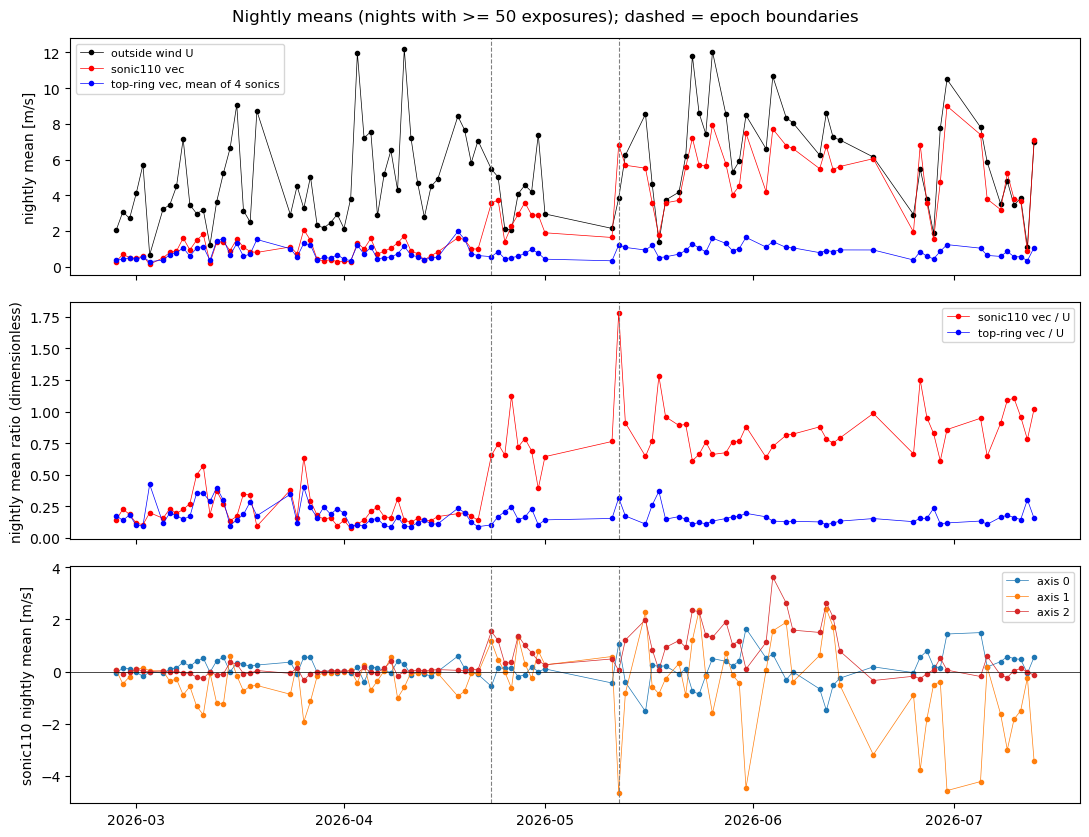

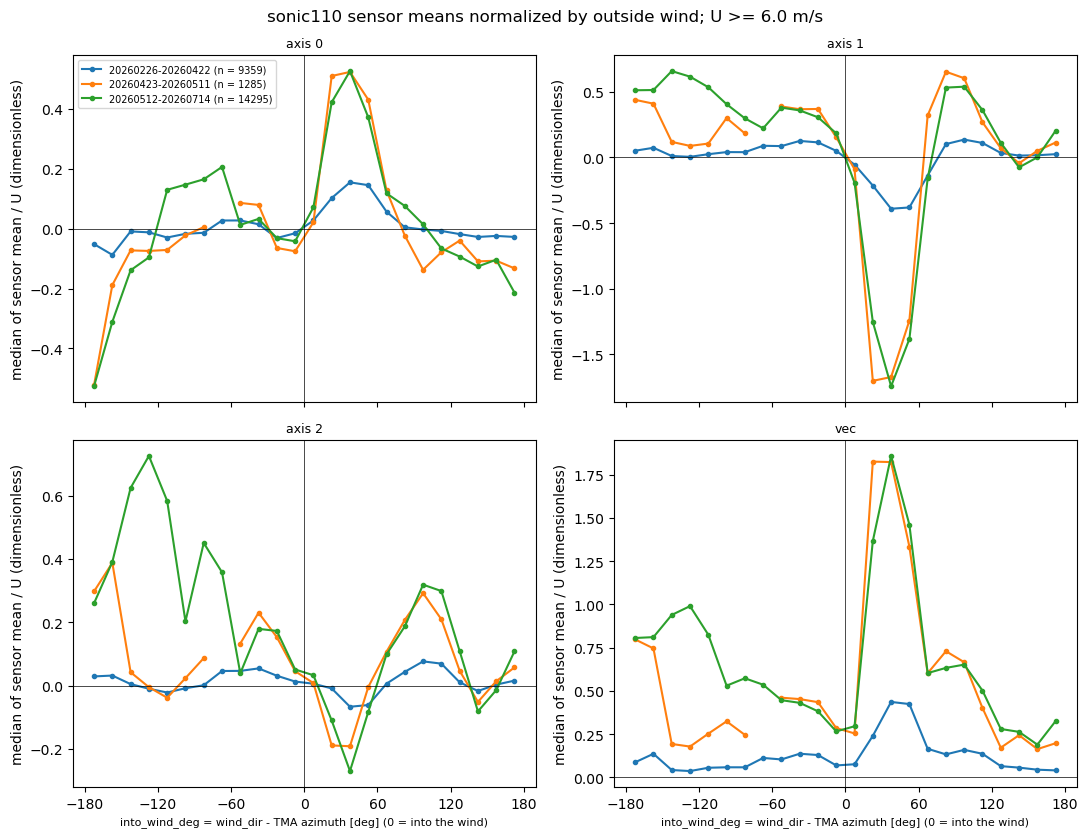

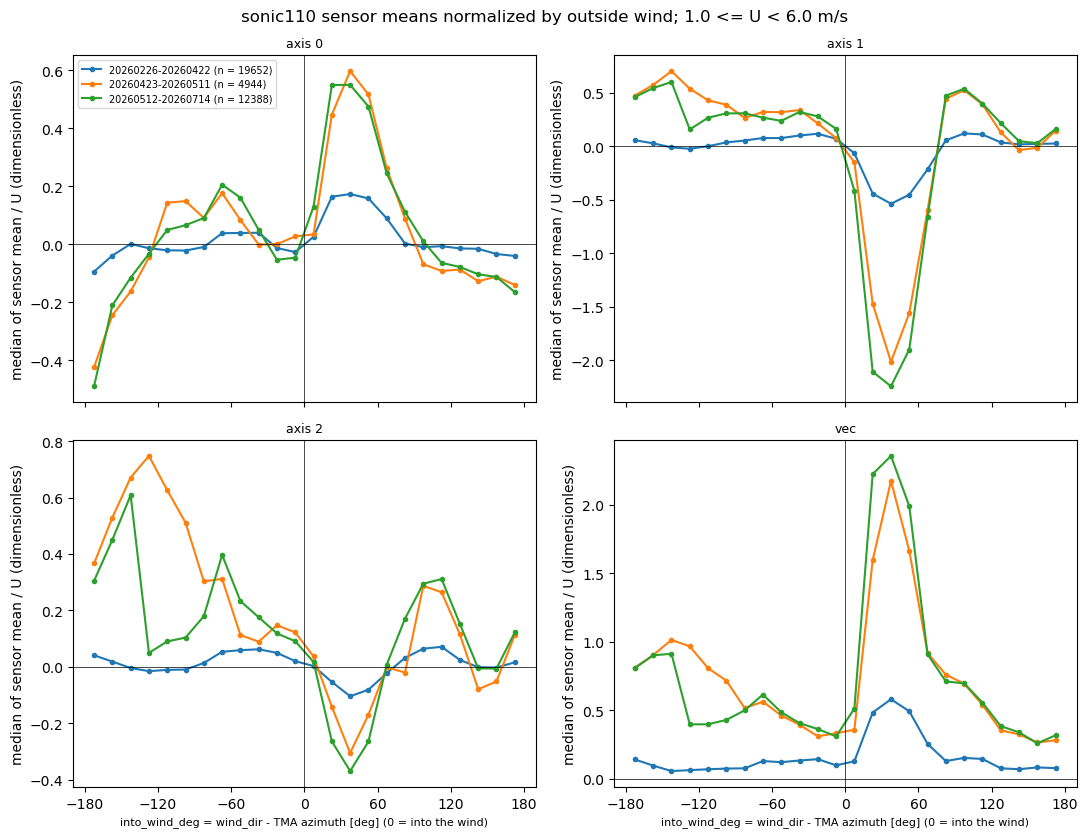

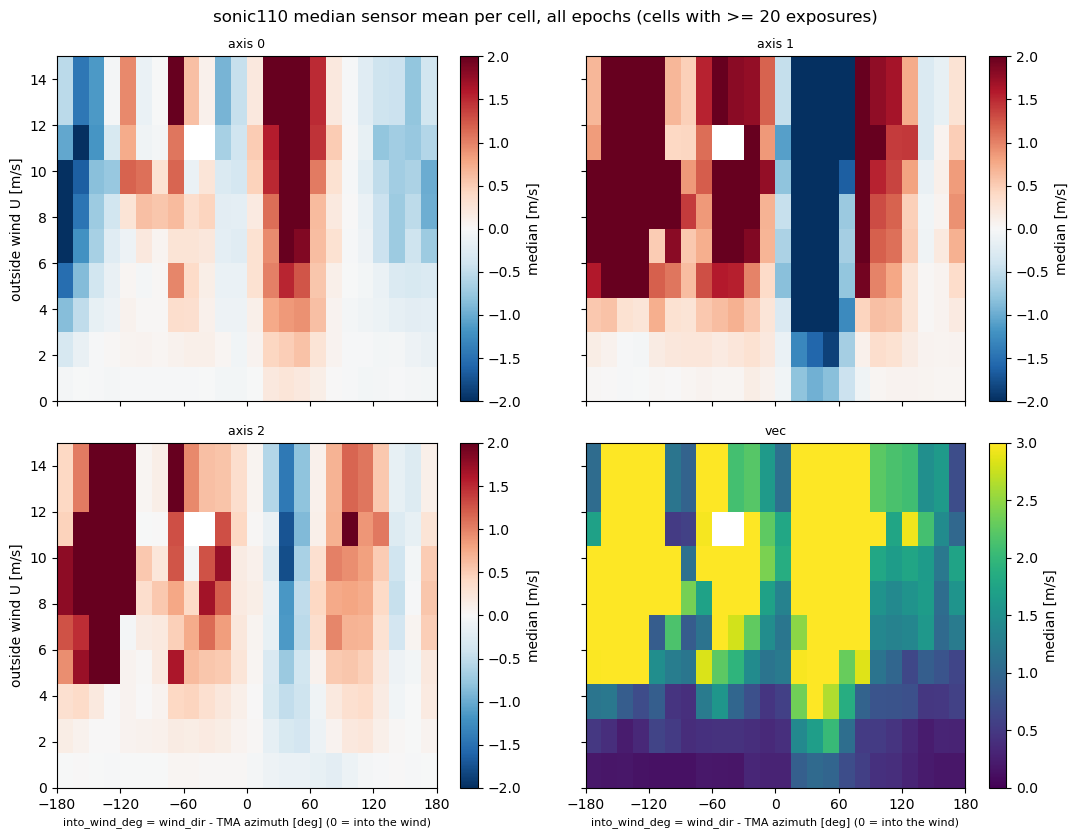

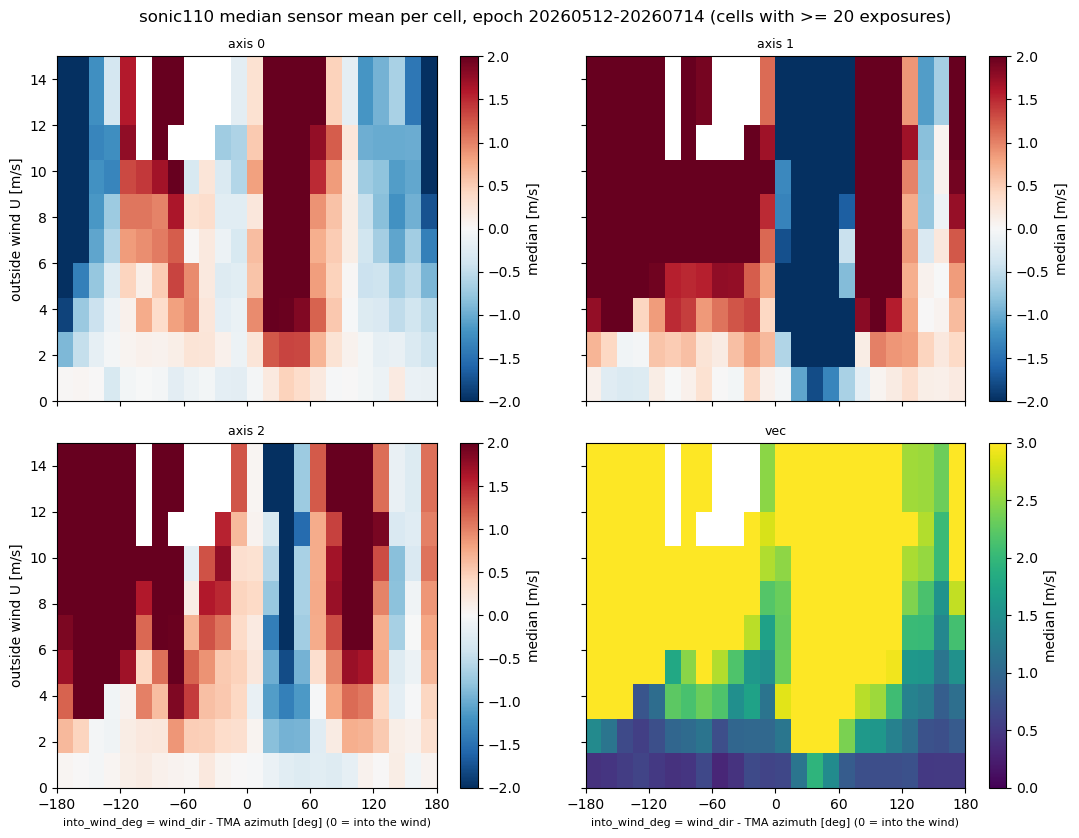

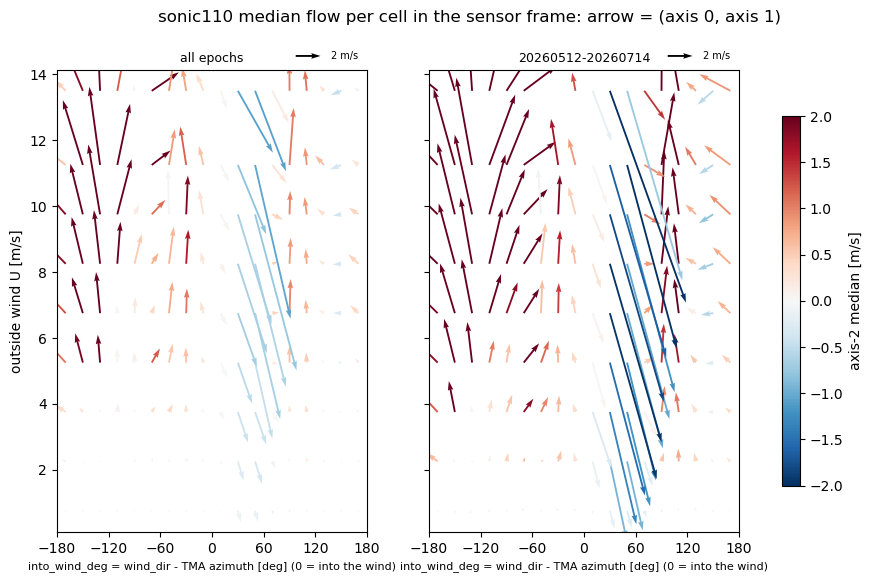

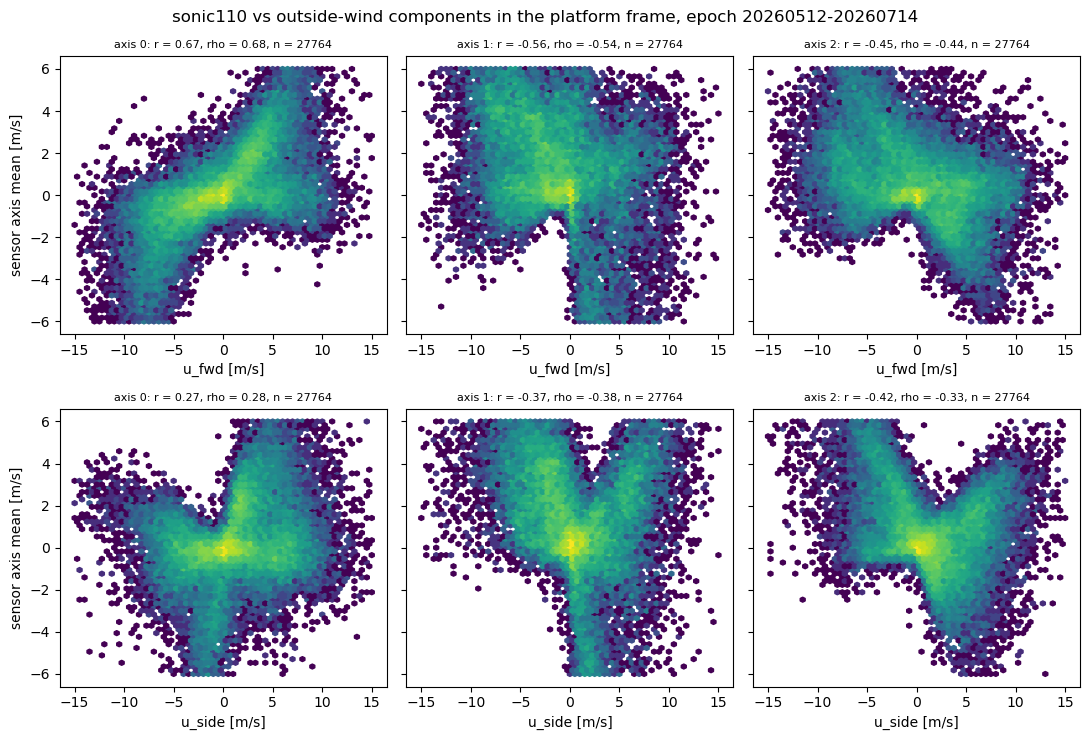

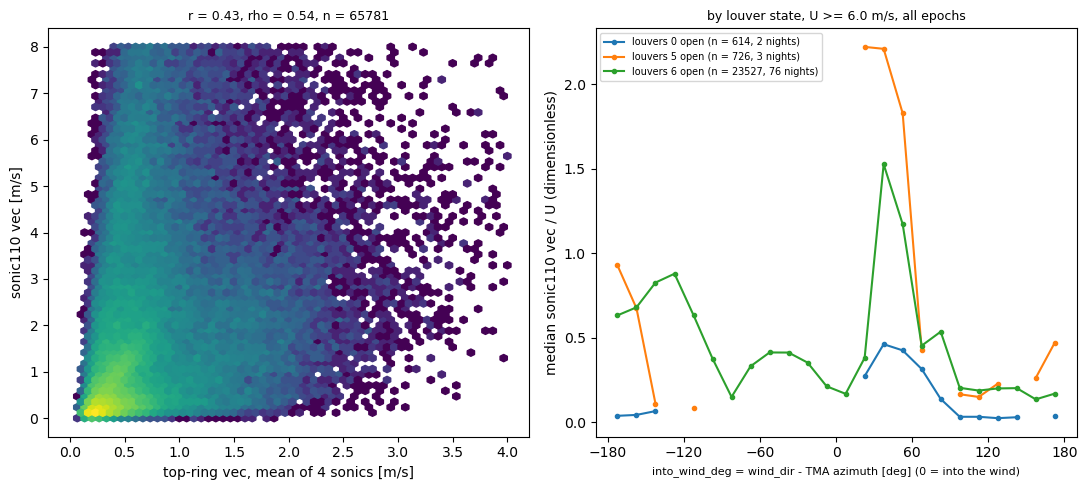

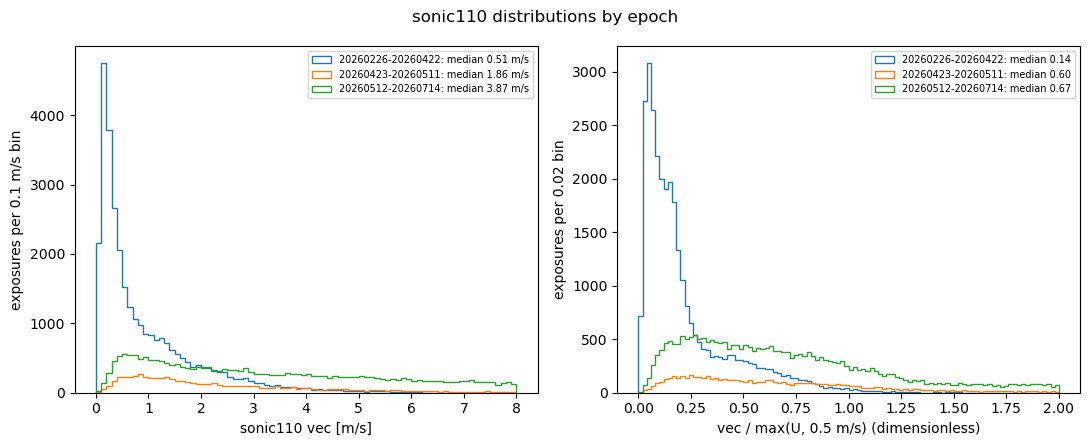

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/airflow/airflow_correlations/20261106_platform_sonic/platform_sonic.pdf


In [6]:
te = np.arange(-180, 181, ANGLE_STEP)
tc = 0.5 * (te[1:] + te[:-1])
ue = np.array(U_EDGES, float)
xt = np.arange(-180, 181, 60)
XL = 'into_wind_deg = wind_dir - TMA azimuth [deg] (0 = into the wind)'
AXC = ('C0', 'C1', 'C3')
pdf = PdfPages(PDF)

# Page 1: summary
body = (f'Sonic {SONIC} (TMA-GillLabJack01) on the deployable-platform railing, +X side, ~2 m above the '
        f'optical axis.\n{len(d)} on-sky exposures, {d.day_obs.nunique()} nights, {d.day_obs.min()}-'
        f'{d.day_obs.max()}; {len(w)} with outside wind U >= {WIND_MIN} m/s.\n'
        'u_fwd = U cos(into_wind), u_side = U sin(into_wind) [m/s]. Sensor orientation unknown.\n'
        'vec = |(axis 0, axis 1, axis 2)| of the exposure means [m/s].\n\n'
        'Huber: axis mean [m/s] = const + c_fwd u_fwd + c_side u_side (c dimensionless, e = error),\n'
        'dir_deg = atan2(c_side, c_fwd) [deg]; r_U, rho_U = Pearson, Spearman vs U [m/s].\n\n'
        + coef.round(3).to_string())
text_page(pdf, f'platform_sonic v1: sonic{SONIC} vs outside wind', body)

# Page 2: nightly time series
fig, axs = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
axs[0].plot(nt.date, nt.U, 'k.-', lw=0.5, label='outside wind U')
axs[0].plot(nt.date, nt.vec, 'r.-', lw=0.5, label=f'sonic{SONIC} vec')
axs[0].plot(nt.date, nt.ring, 'b.-', lw=0.5, label='top-ring vec, mean of 4 sonics')
axs[0].set_ylabel('nightly mean [m/s]'); axs[0].legend(fontsize=8)
axs[1].plot(nt.date, nt.vec / nt.U, 'r.-', lw=0.5, label=f'sonic{SONIC} vec / U')
axs[1].plot(nt.date, nt.ring / nt.U, 'b.-', lw=0.5, label='top-ring vec / U')
axs[1].set_ylabel('nightly mean ratio (dimensionless)'); axs[1].legend(fontsize=8)
for a in range(3):
    axs[2].plot(nt.date, nt[f'ax{a}'], '.-', lw=0.5, color=AXC[a], label=f'axis {a}')
axs[2].axhline(0, color='k', lw=0.5); axs[2].set_ylabel(f'sonic{SONIC} nightly mean [m/s]')
axs[2].legend(fontsize=8)
for ax in axs:
    for lo, hi in EPOCHS[1:]:
        ax.axvline(pd.to_datetime(str(lo)), color='gray', ls='--', lw=0.8)
fig.suptitle(f'Nightly means (nights with >= {NIGHT_MIN} exposures); dashed = epoch boundaries')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Pages 3-4: axis means / U vs into_wind, high and low wind, by epoch
for ws, wlab in ((w, f'U >= {WIND_MIN} m/s'), (wl, f'{WIND_LOW[0]} <= U < {WIND_LOW[1]} m/s')):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True)
    for ax, a in zip(axs.flat, [0, 1, 2, 'vec']):
        for ep, g in ws.groupby('epoch'):
            y = (g[f'{s}_mean_{a}_ms'] if a != 'vec' else g.vec_ms) / g.wind_speed_ms
            c, m, n = binned_median(g.into_wind_deg.to_numpy(), y.to_numpy(), te)
            ax.plot(c, m, 'o-', ms=3, label=f'{ep} (n = {len(g)})')
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
        ax.set_xticks(xt); ax.set_title(f'axis {a}' if a != 'vec' else 'vec', fontsize=9)
        ax.set_ylabel('median of sensor mean / U (dimensionless)')
    axs[0, 0].legend(fontsize=7)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    fig.suptitle(f'sonic{SONIC} sensor means normalized by outside wind; {wlab}')
    fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 5: heat maps, U vs into_wind, last epoch (largest response)
last = d[d.epoch == f'{EPOCHS[-1][0]}-{EPOCHS[-1][1]}']
for gg, glab in ((d, 'all epochs'), (last, f'epoch {EPOCHS[-1][0]}-{EPOCHS[-1][1]}')):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
    for ax, a in zip(axs.flat, [0, 1, 2, 'vec']):
        z = (gg[f'{s}_mean_{a}_ms'] if a != 'vec' else gg.vec_ms).to_numpy()
        m, n = map2d(gg.into_wind_deg.to_numpy(), gg.wind_speed_ms.to_numpy(), z, te, ue)
        lim = 3 if a == 'vec' else 2
        im = ax.pcolormesh(te, ue, m, cmap='viridis' if a == 'vec' else 'RdBu_r',
                           vmin=0 if a == 'vec' else -lim, vmax=lim)
        fig.colorbar(im, ax=ax, label='median [m/s]')
        ax.set_title(f'axis {a}' if a != 'vec' else 'vec', fontsize=9); ax.set_xticks(xt)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('outside wind U [m/s]')
    fig.suptitle(f'sonic{SONIC} median sensor mean per cell, {glab} (cells with >= {MIN_CELL} exposures)')
    fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 7: quiver in (into_wind, U), arrow = (axis 0, axis 1), color = axis 2
qt = np.arange(-180, 181, 20)
fig, axs = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, (gg, glab) in zip(axs, ((d, 'all epochs'), (last, f'{EPOCHS[-1][0]}-{EPOCHS[-1][1]}'))):
    zz = [map2d(gg.into_wind_deg.to_numpy(), gg.wind_speed_ms.to_numpy(),
                gg[f'{s}_mean_{a}_ms'].to_numpy(), qt, ue)[0] for a in range(3)]
    X, Y = np.meshgrid(0.5 * (qt[1:] + qt[:-1]), 0.5 * (ue[1:] + ue[:-1]))
    q = ax.quiver(X, Y, zz[0], zz[1], zz[2], cmap='RdBu_r', clim=(-2, 2), scale=25, width=0.006)
    ax.quiverkey(q, 0.85, 1.03, 2, '2 m/s', labelpos='E', fontproperties={'size': 7})
    ax.set_xticks(xt); ax.set_xlim(-180, 180); ax.set_xlabel(XL, fontsize=8); ax.set_title(glab, fontsize=9)
axs[0].set_ylabel('outside wind U [m/s]')
fig.colorbar(q, ax=axs, label='axis-2 median [m/s]', shrink=0.8)
fig.suptitle(f'sonic{SONIC} median flow per cell in the sensor frame: arrow = (axis 0, axis 1)')
pdf.savefig(fig); plt.show()

# Page 8: sensor means vs u_fwd and u_side, last epoch
fig, axs = plt.subplots(2, 3, figsize=(11, 7.5), sharey=True)
for r_, comp in enumerate(('u_fwd', 'u_side')):
    for a in range(3):
        ax = axs[r_, a]
        y = last[f'{s}_mean_{a}_ms']
        ax.hexbin(last[comp], y, gridsize=60, bins='log', extent=(-15, 15, -6, 6), mincnt=1)
        ok = y.notna()
        ax.set_title(f'axis {a}: r = {stats.pearsonr(last[comp][ok], y[ok])[0]:.2f}, '
                     f'rho = {stats.spearmanr(last[comp][ok], y[ok])[0]:.2f}, n = {ok.sum()}', fontsize=8)
        ax.set_xlabel(f'{comp} [m/s]')
    axs[r_, 0].set_ylabel('sensor axis mean [m/s]')
fig.suptitle(f'sonic{SONIC} vs outside-wind components in the platform frame, epoch '
             f'{EPOCHS[-1][0]}-{EPOCHS[-1][1]}')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 9: platform vs top ring, and by louver state
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
ok = d.ring_vec_ms.notna()
axs[0].hexbin(d.ring_vec_ms[ok], d.vec_ms[ok], gridsize=60, bins='log', extent=(0, 4, 0, 8), mincnt=1)
axs[0].set_xlabel('top-ring vec, mean of 4 sonics [m/s]'); axs[0].set_ylabel(f'sonic{SONIC} vec [m/s]')
axs[0].set_title(f'r = {stats.pearsonr(d.ring_vec_ms[ok], d.vec_ms[ok])[0]:.2f}, rho = '
                 f'{stats.spearmanr(d.ring_vec_ms[ok], d.vec_ms[ok])[0]:.2f}, n = {ok.sum()}', fontsize=9)
for lo, hi, lab in LOUVER_STATES:
    g = w[w.louver_state == lab]
    c, m, n = binned_median(g.into_wind_deg.to_numpy(), (g.vec_ms / g.wind_speed_ms).to_numpy(), te)
    axs[1].plot(c, m, 'o-', ms=3, label=f'louvers {lab} (n = {len(g)}, {g.day_obs.nunique()} nights)')
axs[1].set_xticks(xt); axs[1].set_xlabel(XL, fontsize=8); axs[1].legend(fontsize=7)
axs[1].set_ylabel(f'median sonic{SONIC} vec / U (dimensionless)')
axs[1].set_title(f'by louver state, U >= {WIND_MIN} m/s, all epochs', fontsize=9)
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 10: histograms
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ep, g in d.groupby('epoch'):
    axs[0].hist(g.vec_ms, bins=np.arange(0, 8.05, 0.1), histtype='step',
                label=f'{ep}: median {g.vec_ms.median():.2f} m/s')
    axs[1].hist(g.vec_ms / g.wind_speed_ms.clip(lower=0.5), bins=np.arange(0, 2.02, 0.02), histtype='step',
                label=f'{ep}: median {(g.vec_ms / g.wind_speed_ms.clip(lower=0.5)).median():.2f}')
axs[0].set_xlabel(f'sonic{SONIC} vec [m/s]'); axs[0].set_ylabel('exposures per 0.1 m/s bin')
axs[1].set_xlabel('vec / max(U, 0.5 m/s) (dimensionless)'); axs[1].set_ylabel('exposures per 0.02 bin')
for ax in axs: ax.legend(fontsize=7)
fig.suptitle(f'sonic{SONIC} distributions by epoch'); fig.tight_layout(); pdf.savefig(fig); plt.show()
pdf.close()
print(PDF)